<a href="https://colab.research.google.com/github/KTada777/Bayesian_SolarCell_1D-Citrcuit/blob/main/260725_pymc5%2Bnutpie_PVparameter_OPV_0_03sun.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!cat /proc/cpuinfo | awk '/processor/,/cpu MHz/'

processor	: 0
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2199.998
processor	: 1
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2199.998


In [ ]:
import sys
print(sys.version)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [ ]:
!pip install nutpie

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 58.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 87.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 102.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.6/319.6 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 58.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.9/243.9 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.8/183.8 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 102.7 MB/s eta 0:00:00
  Attempting uninstall: arviz
    Found existing installation: arviz 0.22.0
    Uninstalling arviz-0.22.0:
      Successfully uninstalled arviz-0.22.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pymc 5.28.5 requires arviz<1.0,>=0.13.0, but 

In [ ]:
!pip install pymc
import pymc as pm
print(pm.__version__)
import arviz as az

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 20.0 MB/s eta 0:00:00
  Attempting uninstall: arviz
    Found existing installation: arviz 1.2.0
    Uninstalling arviz-1.2.0:
      Successfully uninstalled arviz-1.2.0
5.28.5


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

In [ ]:
import pytensor
pytensor.config.optdb__max_use_ratio = 40.0

In [ ]:
def pm_I_Roberts_g(Iph, Rp, Rs, I0, n, V):
    Iph = Iph / 1000  #mA
    Rs = Rs / 1e3     #mOhm
    I0 = I0 / 1e9     #nA
    nVt = n*0.026    #Vt(RT)=26 mV
    x = np.log(I0 * (Rs * Rp) / (Rs + Rp) / nVt) + (Rp / (Rs + Rp)) * (V + Rs * (I0 + Iph)) / nVt

    return (V - nVt * (pm_Roberts_g(x) - np.log(I0 * Rs * Rp / (Rs + Rp) / nVt))) / Rs

In [ ]:
def pm_Roberts_g(x):
    e_1 = np.exp(-1)
    e1 = np.exp(1)
    g = pm.math.switch((x <= -(e_1)), x, pm.math.switch((x >= e1), np.log(x), -e1 + (1 + e1) / (2 * e1) * (x + e1)))
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    return g

In [ ]:
#
# J-V of PTB7-Th:C70 OPV @0.03 sun.
#
X = np.array([
    0.769999, 0.76, 0.75, 0.739999, 0.73, 0.72, 0.71,
    0.7, 0.69, 0.679999, 0.67, 0.66, 0.65, 0.64,
    0.629999, 0.62, 0.609999, 0.599999, 0.59, 0.58, 0.569999,
    0.559999, 0.55, 0.539999, 0.53, 0.52, 0.51, 0.5,
    0.489999, 0.479999, 0.47, 0.46, 0.449999, 0.44, 0.429999,
    0.42, 0.41, 0.4, 0.389999, 0.379999, 0.37, 0.359999,
    0.349999, 0.34, 0.33, 0.319999, 0.31, 0.3, 0.289999,
    0.279999, 0.269999, 0.26, 0.25, 0.239999, 0.229999, 0.22,
    0.21, 0.2, 0.189999, 0.179999, 0.17, 0.16, 0.15,
    0.14, 0.13, 0.119999, 0.109999, 0.1, 0.089999, 0.079999,
    0.069999, 0.059999, 0.049999, 0.039999, 0.029999, 0.02, 0.01,
    0.0, 0.0, -0.01, -0.020001, -0.03, -0.040001, -0.050001,
    -0.060001, -0.07, -0.08, -0.090001, -0.1, -0.11, -0.12,
    -0.130001, -0.14, -0.15, -0.16, -0.170001, -0.180001, -0.190001,
    -0.200001
])

Y = np.array([
    0.00383534, 0.00330502, 0.00281177, 0.00235714, 0.001943, 0.00157089,
    0.00124094, 0.00095331, 0.00070626, 0.00049738, 0.00032326, 0.0001804,
    0.00006474, -0.00002811, -0.0001023, -0.00016074, -0.00020699, -0.00024352,
    -0.00027201, -0.00029499, -0.00031304, -0.00032733, -0.0003392, -0.00034839,
    -0.00035651, -0.00036269, -0.00036833, -0.000373, -0.00037714, -0.00038052,
    -0.00038399, -0.00038694, -0.00038921, -0.00039171, -0.00039372, -0.00039596,
    -0.00039778, -0.00039988, -0.00040157, -0.00040311, -0.00040443, -0.00040612,
    -0.00040746, -0.00040843, -0.00041004, -0.00041103, -0.00041266, -0.00041374,
    -0.00041499, -0.00041571, -0.00041694, -0.00041788, -0.00041913, -0.00042002,
    -0.00042109, -0.00042199, -0.00042322, -0.00042382, -0.00042472, -0.00042547,
    -0.00042613, -0.00042733, -0.00042798, -0.00042861, -0.00042924, -0.00043033,
    -0.00043092, -0.00043166, -0.00043218, -0.00043303, -0.00043354, -0.00043414,
    -0.00043486, -0.0004357, -0.00043611, -0.00043688, -0.00043766, -0.00043803,
    -0.00043836, -0.00043879, -0.00043919, -0.00043968, -0.00044046, -0.00044099,
    -0.00044152, -0.00044216, -0.00044268, -0.00044328, -0.00044347, -0.00044393,
    -0.00044477, -0.00044547, -0.00044578, -0.00044614, -0.00044663, -0.00044723,
    -0.00044773, -0.00044839, -0.00044859
])

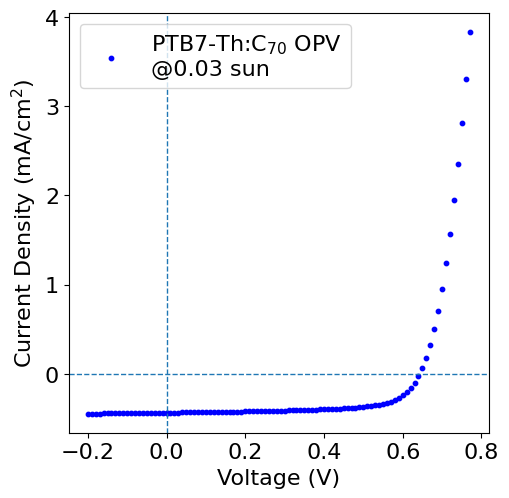

In [ ]:
######################################
plt.rcParams['font.size'] = 16
#
fig = plt.figure( figsize=(6,6) )
fig.subplots_adjust(left=0.22, right=0.92,
                    top=0.9, bottom=0.2)
#
ax1 = fig.add_subplot(1,1,1)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Current Density (mA/cm$^{2}$)')
#
ax1.scatter(X, Y*1e3, color='blue',
            s=10.0,
            label='PTB7-Th:C$_{70}$ OPV\n@0.03 sun'
           )
#
(x_left, x_right) = ax1.set_xlim()
(y_bot, y_top) = ax1.set_ylim()
#
ax1.hlines(0, x_left, x_right,
           linestyles='dashed', linewidth=1.0)
ax1.vlines(0, y_bot, y_top,
           linestyles='dashed', linewidth=1.0)
#
plt.legend()

In [ ]:
#
t0 = time.perf_counter()
#
with pm.Model() as model:
    Iph = pm.Uniform('Iph', lower=1e-4, upper=1e2 )  #mA
    Rp = pm.Uniform('Rp', lower=1e0, upper=1e8)      #Ohm
    Rs = pm.Uniform('Rs', lower=1e0, upper=1e8 )     #mOhm
    I0 = pm.Uniform('I0', lower=1e-4, upper=1e6 )    #nA
    n = pm.Uniform('n', lower=0.5, upper=500 )       #Vt(RT)=26 mV
#
    rmsd = pm.Uniform('rmsd', lower=0, upper=1e-2)
    mu = pm_I_Roberts_g(Iph, Rp, Rs, I0, n, X)
#
    y = pm.Normal('y', mu=mu, sigma=rmsd, observed=Y)
#
    trace = pm.sample(10000, tune=10000, chains=2, nuts_sampler='nutpie', target_accept=0.99)
#
t1 = time.perf_counter()
print( "elapsed time %.3f sec" % (t1-t0)  )

Progress,Draws,Divergences,Step Size,Gradients/Draw
,20000,0,0.03,255
,20000,0,0.03,127


elapsed time 839.894 sec


In [ ]:
def Roberts_g(x):
    if x <= -(np.exp(-1)):
        g = x
    elif x >= (np.exp(1)):
        g = np.log(x)
    else:
        g = -np.exp(1) + (1 + np.exp(1)) / (2 * np.exp(1)) * (x + np.exp(1))
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    eg = np.exp(g)
    g = g - (2 * (g + eg - x) * (1 + eg)) / (2 * (1 + eg) ** 2 - (g + eg - x) * eg)
#
    return g

In [ ]:
def I_Roberts_g(Iph, Rp, Rs, I0, n, V):
    Iph = Iph / 1000  #mA
    Rs = Rs / 1e3     #mOhm
    I0 = I0 / 1e9     #nA
    nVt = n*0.026     #Vt(RT)=26 mV
    LogQ = np.log(I0 * (Rs * Rp) / (Rs + Rp) / nVt) + (Rp / (Rs + Rp)) * (V + Rs * (I0 + Iph)) / nVt
    return (V - nVt * (Roberts_g(LogQ) - np.log(I0 * Rs * Rp / (Rs + Rp) / nVt))) / Rs

In [ ]:
def calcI(Iph, Rp, Rs, I0, n, V):
    V_list = V.tolist()
    I_list = [I_Roberts_g(Iph, Rp, Rs, I0, n, item) for item in V_list]
    return np.array(I_list)

In [ ]:
az.summary(trace).style.format("{:.2e}")

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
I0,2.30e-02,3.00e-03,1.80e-02,2.80e-02,0.00e+00,0.00e+00,1.87e+03,2.04e+03,1.00e+00
Iph,4.38e-01,1.00e-03,4.36e-01,4.39e-01,0.00e+00,0.00e+00,1.01e+04,1.15e+04,1.00e+00
Rp,1.05e+04,2.92e+02,9.93e+03,1.10e+04,4.19e+00,2.61e+00,4.85e+03,7.50e+03,1.00e+00
Rs,8.78e+03,1.16e+02,8.56e+03,9.00e+03,2.52e+00,1.92e+00,2.12e+03,2.24e+03,1.00e+00
n,1.49e+00,1.00e-02,1.47e+00,1.50e+00,0.00e+00,0.00e+00,1.87e+03,2.03e+03,1.00e+00
rmsd,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,1.58e+04,1.24e+04,1.00e+00


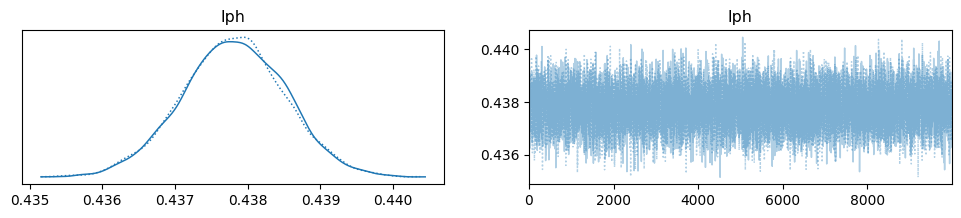

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Iph'))

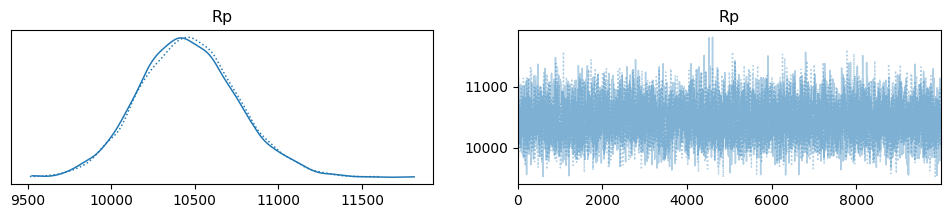

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Rp'))

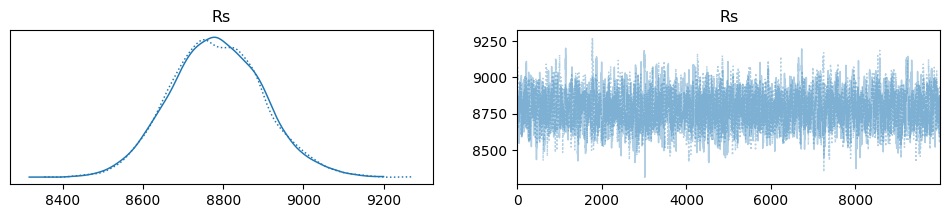

In [ ]:
with model:
  az.plot_trace(trace, var_names=('Rs'))

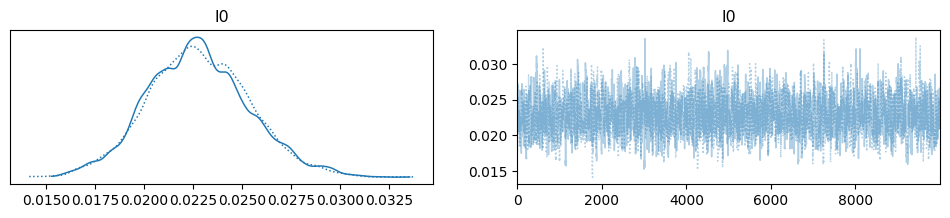

In [ ]:
with model:
  az.plot_trace(trace, var_names=('I0'))

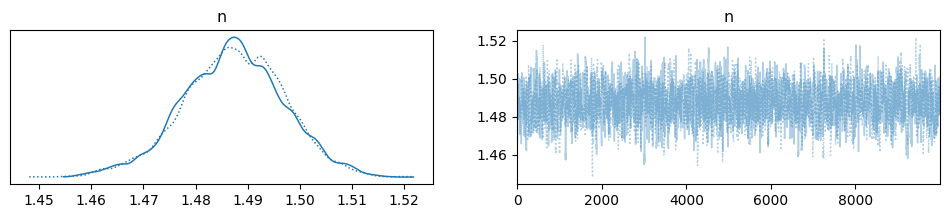

In [ ]:
with model:
  az.plot_trace(trace, var_names=('n'))

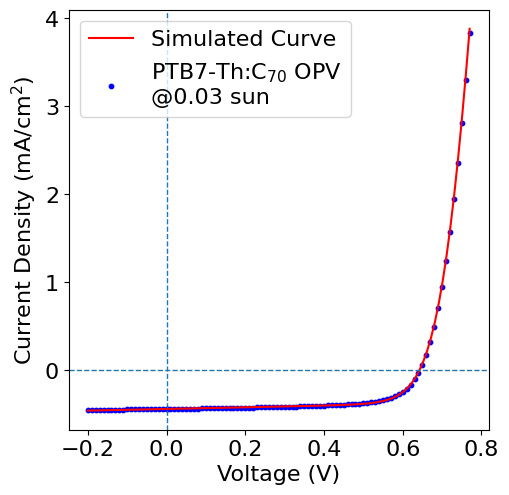

In [ ]:
######################################
plt.rcParams['font.size'] = 16
#
fig = plt.figure( figsize=(6,6) )
fig.subplots_adjust(left=0.22, right=0.92,
                    top=0.9, bottom=0.2)
#
ax1 = fig.add_subplot(1,1,1)
ax1.set_xlabel('Voltage (V)')
ax1.set_ylabel('Current Density (mA/cm$^{2}$)')
#
ax1.scatter(X, Y*1e3, color='blue',
            s=10.0,
            label='PTB7-Th:C$_{70}$ OPV\n@0.03 sun'
           )

xmin = np.amin(X)
xmax = np.amax(X)
N = 100
X_range = np.linspace(xmin, xmax, num=N, endpoint=True )

Q = az.summary(trace)
Iph_m = Q.loc['Iph','mean']
Rp_m = Q.loc['Rp','mean']
Rs_m = Q.loc['Rs','mean']
I0_m = Q.loc['I0','mean']
n_m = Q.loc['n','mean']
I_list = calcI(Iph_m, Rp_m, Rs_m, I0_m, n_m, X_range)

ax1.plot(X_range, I_list*1e3, color='red',
            label='Simulated Curve'
           )

#
(x_left, x_right) = ax1.set_xlim()
(y_bot, y_top) = ax1.set_ylim()
#
ax1.hlines(0, x_left, x_right,
           linestyles='dashed', linewidth=1.0)
ax1.vlines(0, y_bot, y_top,
           linestyles='dashed', linewidth=1.0)
#
handles, labels = ax1.get_legend_handles_labels()
plt.legend(handles[::-1], labels[::-1])